<a href="https://colab.research.google.com/github/bsheese/387/blob/main/22_images/22_1_Transfer_Learning/22_1_1_Transfer_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Images: Part 3
## Transfer Learning: Opening Up the 19_0 Model

---

## What This Notebook Is About

On the first day of the course you took ResNet-18, a network pretrained on 1.2 million ImageNet photos, replaced its last layer, and trained only that layer on 400 photos of four pet breeds. It got 90% of the test photos right, and we treated the whole thing as a black box. You now know every part of what happened, so this notebook opens it up:

1. What ResNet-18 is: a deep CNN built from the same layers as 22_0_2's, plus one new idea, the **residual connection**
2. What its layers have learned, from the filters of its first layer to the feature maps of its last
3. Why reusing it worked: a CNN trained **from scratch** on the same 400 photos does far worse
4. **Fine-tuning** more of the network, with data augmentation, and how to judge whether it helped
5. How to choose between these approaches for a new problem

Reusing a network trained on one task for another task is called **transfer learning**, and it's how most image models are built in practice.

This notebook trains two networks on photos. On Colab's GPU (Runtime → Change runtime type → T4 GPU) each takes under a minute; on a CPU each takes several minutes. The notebook is saved with its outputs, so you can read the results before running anything.

In [1]:
import os
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision import datasets, models, transforms as T
from PIL import Image

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

DATA_URL = 'https://raw.githubusercontent.com/bsheese/387/main/data/'

def fetch(name):
    # Download a file from the course's data folder, unless it is already here.
    if not os.path.exists(name):
        urllib.request.urlretrieve(DATA_URL + name, name)
    return name

with zipfile.ZipFile(fetch('pets4.zip')) as z:
    z.extractall('.')
BREEDS = sorted(os.listdir('pets4/train'))

weights = models.ResNet18_Weights.DEFAULT
preprocess = weights.transforms()
resnet = models.resnet18(weights=weights).to(device).eval()
loss_fn = nn.CrossEntropyLoss()
print(BREEDS)

device: cpu


['Birman', 'Ragdoll', 'basset_hound', 'beagle']


---

## Section 1: Inside ResNet-18

20_1_1 listed ResNet-18's weight tensors. Here is the path of one photo through its main parts, with the shape after each one, the way 22_0_2 followed a Fashion-MNIST image through a small CNN:

In [2]:
photo = Image.open('pets4/test/beagle/' + sorted(os.listdir('pets4/test/beagle'))[0]).convert('RGB')
x = preprocess(photo).unsqueeze(0).to(device)

print(f'{"input":10} {tuple(x.shape)}')
with torch.no_grad():
    for name in ['conv1', 'bn1', 'relu', 'maxpool', 'layer1', 'layer2', 'layer3', 'layer4', 'avgpool']:
        x = getattr(resnet, name)(x)
        print(f'{name:10} {tuple(x.shape)}')
    x = torch.flatten(x, 1)
    print(f'{"flatten":10} {tuple(x.shape)}')
    print(f'{"fc":10} {tuple(resnet.fc(x).shape)}')

input      (1, 3, 224, 224)
conv1      (1, 64, 112, 112)
bn1        (1, 64, 112, 112)
relu       (1, 64, 112, 112)
maxpool    (1, 64, 56, 56)
layer1     (1, 64, 56, 56)
layer2     (1, 128, 28, 28)
layer3     (1, 256, 14, 14)
layer4     (1, 512, 7, 7)
avgpool    (1, 512, 1, 1)
flatten    (1, 512)
fc         (1, 1000)


The pattern is the one from 22_0: the image gets smaller while the number of channels grows.

- **conv1** is a 7 × 7 convolution with 64 filters and stride 2, and **maxpool** halves the size again: 224 → 112 → 56.
- **layer1** to **layer4** are each two **residual blocks** (below). Each of layer2, layer3 and layer4 halves the size and doubles the channels, ending at 512 feature maps of 7 × 7.
- **avgpool** averages each 7 × 7 feature map down to one number. This is **global average pooling**, and it produces the 512 **features** from 19_0_2.
- **fc** is the last layer, `nn.Linear(512, 1000)`, which 19_0_1 replaced.

### Residual connections

Here is one of the residual blocks:

In [3]:
print(resnet.layer1[0])

BasicBlock(
  (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
)


The block has two 3 × 3 convolutions, each followed by batch norm, which is familiar from 22_0_2. What the printout doesn't show is in the block's `forward`: the block's input is **added** to the output of the second batch norm before the final ReLU:

$$\text{output} = \text{ReLU}(\text{convolutions}(x) + x)$$

That addition is the **residual connection** (or skip connection), and it's the "Res" in ResNet. It means each block only has to learn a correction to its input rather than a whole new representation, and it gives the slopes a direct path backward through the network. Recall from 20_0_2 that rates multiply: a slope that passes back through many layers is a product of many rates, and if those rates are mostly below 1, the product shrinks toward 0 and the early layers barely learn. The `+ x` path has a rate of exactly 1, so slopes can reach the early layers undiminished. Before residual connections were introduced in 2015, networks much deeper than about 20 layers were very hard to train; with them, ResNets of over 100 layers trained well.

---

## Section 2: What the Layers Learned

The first layer, conv1, has 64 filters, each 7 × 7 over the 3 color channels. Because they look at color pixels directly, they can be shown as small color images:

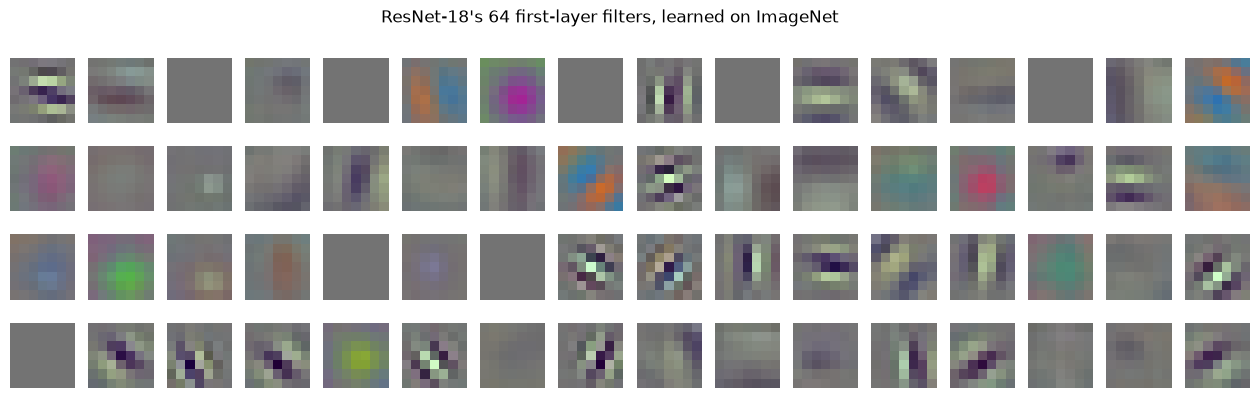

In [4]:
filters = resnet.conv1.weight.detach().cpu()              # (64, 3, 7, 7)
filters = (filters - filters.min()) / (filters.max() - filters.min())   # rescale to 0-1 for display
fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))
for ax, f in zip(axes.flat, filters):
    ax.imshow(f.permute(1, 2, 0))                          # (3, 7, 7) -> (7, 7, 3) for imshow
    ax.axis('off')
plt.suptitle("ResNet-18's 64 first-layer filters, learned on ImageNet")
plt.show()

Some are nearly flat gray, filters that ended up contributing little. Many of the others are edge detectors at different angles, like 22_0_2's learned filters but larger and in color. Others respond to particular colors, or to color changes such as green next to purple, and some look like small striped patterns. These simple features are useful for almost any photo, which is the first reason transfer learning works.

Later layers combine them into more specific features. Here are some of the feature maps for the beagle photo after layer1 (56 × 56, early) and after layer4 (7 × 7, the last before pooling):

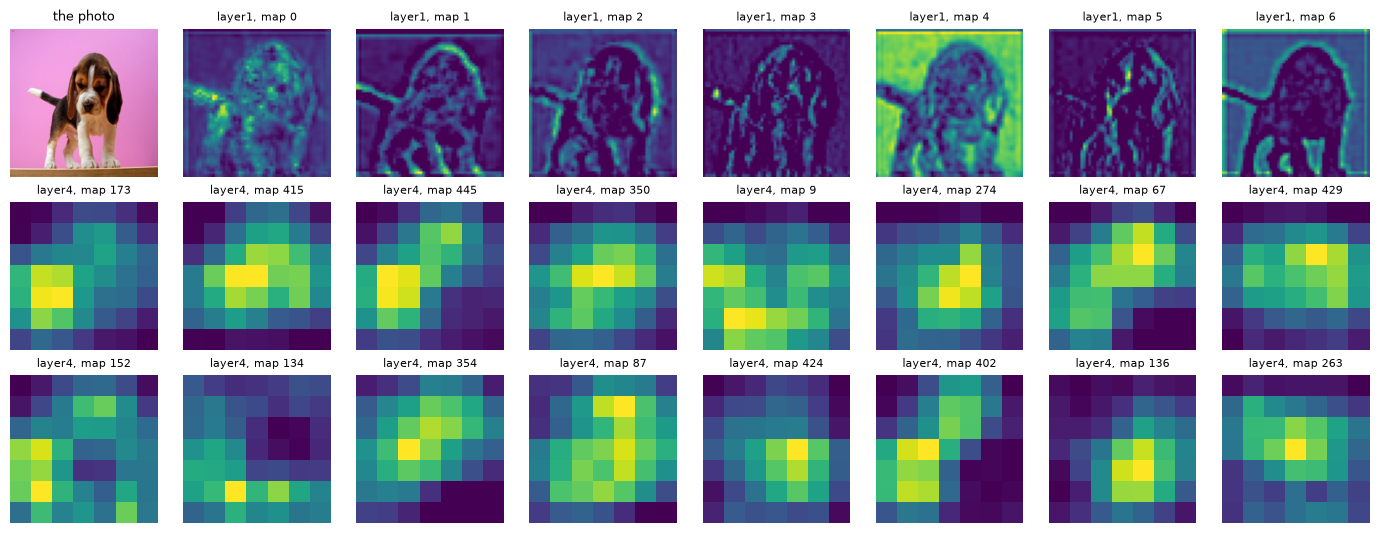

In [5]:
x = preprocess(photo).unsqueeze(0).to(device)
with torch.no_grad():
    early = resnet.layer1(resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x)))))
    late = resnet.layer4(resnet.layer3(resnet.layer2(early)))

fig, axes = plt.subplots(3, 8, figsize=(14, 5.4))
axes[0, 0].imshow(photo.resize((224, 224)))
axes[0, 0].set_title('the photo', fontsize=9)
for i, ax in enumerate(axes[0, 1:]):
    ax.imshow(early[0, i].cpu(), cmap='viridis')
    ax.set_title(f'layer1, map {i}', fontsize=8)
strongest = late[0].mean(dim=(1, 2)).argsort(descending=True)[:16]   # the layer4 maps that respond most
for ax, i in zip(axes[1:].flat, strongest):
    ax.imshow(late[0, i].cpu(), cmap='viridis')
    ax.set_title(f'layer4, map {i.item()}', fontsize=8)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

The layer1 maps are sharp and look like the photo with different parts emphasized: outlines, fur texture, the dark patches. The layer4 maps are only 7 × 7, so each value summarizes a large region of the photo, and each map responds strongly in a few places, often on the dog's head or body rather than the background. Each of the 512 layer4 maps has learned to respond to some combination of shapes and textures that helped classify ImageNet's 1,000 categories, many of which are animals. Averaging each map gives one number per map: the 512 features that 19_0's last layer used to tell the breeds apart.

---

## Section 3: Training a CNN From Scratch

How much did ImageNet actually help? To find out, train a CNN of the 22_0_2 kind directly on the 400 Pets training photos, with no pretraining. It has four convolutional blocks, so it can handle larger photos; to keep it fast the photos are shrunk to 112 × 112, and it ends with global average pooling like ResNet. It uses augmentation (random crops, flips and color changes) because 400 photos is very little data.

In [6]:
normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
small_plain = T.Compose([T.Resize(128), T.CenterCrop(112), T.ToTensor(), normalize])
small_augment = T.Compose([T.RandomResizedCrop(112, scale=(0.5, 1.0)), T.RandomHorizontalFlip(),
                           T.ColorJitter(0.3, 0.3, 0.3), T.ToTensor(), normalize])

def loader(split, transform, shuffle=False):
    return torch.utils.data.DataLoader(datasets.ImageFolder(f'pets4/{split}', transform), batch_size=32, shuffle=shuffle)

def accuracy(model, data_loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in data_loader:
            correct += (model(x.to(device)).argmax(dim=1) == y.to(device)).sum().item()
            total += len(y)
    return correct / total

def block(c_in, c_out):
    return [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(), nn.MaxPool2d(2)]

torch.manual_seed(0)
scratch = nn.Sequential(*block(3, 32), *block(32, 64), *block(64, 128), *block(128, 128),
                        nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 4)).to(device)
print(f'{sum(p.numel() for p in scratch.parameters()):,} weights')

EPOCHS = 25
train_loader = loader('train', small_augment, shuffle=True)
optimizer = torch.optim.AdamW(scratch.parameters(), lr=0.001, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
for epoch in range(1, EPOCHS + 1):
    scratch.train()
    for x, y in train_loader:
        optimizer.zero_grad()
        loss_fn(scratch(x.to(device)), y.to(device)).backward()
        optimizer.step()
    scheduler.step()
    if epoch % 5 == 0:
        print(f"epoch {epoch}: training accuracy {accuracy(scratch, loader('train', small_plain)):.3f}, "
              f"validation accuracy {accuracy(scratch, loader('val', small_plain)):.3f}")

scratch_test = accuracy(scratch, loader('test', small_plain))
print(f'from scratch, test accuracy: {scratch_test:.3f}')

242,052 weights


epoch 5: training accuracy 0.497, validation accuracy 0.475


epoch 10: training accuracy 0.557, validation accuracy 0.480


epoch 15: training accuracy 0.708, validation accuracy 0.610


epoch 20: training accuracy 0.752, validation accuracy 0.620


epoch 25: training accuracy 0.740, validation accuracy 0.635


from scratch, test accuracy: 0.655


(`nn.AdaptiveAvgPool2d(1)` is global average pooling: it averages each feature map to a single number, whatever its size.)

Trained from scratch, the CNN gets about two-thirds of the test photos right. That's well above the 0.25 baseline from 19_1_1, so it learned something real, but it's far below the 0.90 that 19_0's model got by training a single layer. Four hundred photos aren't enough to learn good features from nothing: what an edge is, what fur looks like, what makes a face a face. ResNet-18 learned those from 1.2 million photos, and transfer learning lets a new problem borrow them.

---

## Section 4: Two Ways to Reuse a Pretrained Network

### Feature extraction (what 19_0 did)

**Feature extraction** freezes the whole pretrained network and trains only a new last layer on its features. That's what 19_0_1 did, and it's what 19_1_3 showed is just logistic regression on the 512 features. Its results were saved in 19_0_2:

In [7]:
preds = pd.read_csv(fetch('pets4_predictions.csv'))
test_rows = preds[preds['split'] == 'test']
frozen_test = (test_rows['breed'] == test_rows['predicted']).mean()
print(f'feature extraction (19_0), test accuracy: {frozen_test:.3f}')

feature extraction (19_0), test accuracy: 0.900


### Fine-tuning

**Fine-tuning** goes further: it lets some of the pretrained layers change too, so their features can adapt to the new problem. The usual approach, and the one used here:

- Unfreeze only the **last** part of the network (here layer4). Early layers detect general things like edges that suit any photos; the last layers detect the most ImageNet-specific features, so they have the most to gain from adjusting.
- Give the pretrained layers a **smaller learning rate** than the new last layer (0.0001 instead of 0.001), so training adjusts them gently instead of overwriting what they learned. An optimizer can take different learning rates for different groups of weights.
- Keep the frozen layers in evaluation mode during training, so their batch-norm running averages stay as they were learned on ImageNet. This is the issue from 21_1_1 and 19_0_1. The unfrozen layer4 is put in training mode, so its batch-norm layers adapt along with its weights.
- Use augmentation, at the full 224 × 224 size.

In [8]:
augment = T.Compose([T.RandomResizedCrop(224, scale=(0.6, 1.0)), T.RandomHorizontalFlip(),
                     T.ColorJitter(0.3, 0.3, 0.3), T.ToTensor(), normalize])

torch.manual_seed(0)
model = models.resnet18(weights=weights)
model.fc = nn.Linear(512, 4)
model = model.to(device)
for name, p in model.named_parameters():
    p.requires_grad = name.startswith('layer4') or name.startswith('fc')    # everything else stays frozen
print(f"trainable weights: {sum(p.numel() for p in model.parameters() if p.requires_grad):,} of "
      f"{sum(p.numel() for p in model.parameters()):,}")

optimizer = torch.optim.AdamW([
    {'params': model.layer4.parameters(), 'lr': 0.0001},    # pretrained: small steps
    {'params': model.fc.parameters(), 'lr': 0.001},         # new: normal steps
], weight_decay=0.01)

train_loader = loader('train', augment, shuffle=True)
val_loader, test_loader = loader('val', preprocess), loader('test', preprocess)
best_val, best_state = 0, None
for epoch in range(1, 6):
    model.eval()                   # frozen layers: keep ImageNet's batch-norm averages
    model.layer4.train()           # the layer being fine-tuned: training behavior
    for x, y in train_loader:
        optimizer.zero_grad()
        loss_fn(model(x.to(device)), y.to(device)).backward()
        optimizer.step()
    val_acc = accuracy(model, val_loader)
    if val_acc > best_val:
        best_val, best_state = val_acc, {k: v.clone() for k, v in model.state_dict().items()}
    print(f'epoch {epoch}: validation accuracy {val_acc:.3f}')

model.load_state_dict(best_state)
finetuned_test = accuracy(model, test_loader)
print(f'fine-tuned layer4, test accuracy: {finetuned_test:.3f}')

trainable weights: 8,395,780 of 11,178,564


epoch 1: validation accuracy 0.780


epoch 2: validation accuracy 0.910


epoch 3: validation accuracy 0.905


epoch 4: validation accuracy 0.905


epoch 5: validation accuracy 0.910


fine-tuned layer4, test accuracy: 0.920


Over 8 million weights are now trainable, about three-quarters of the network (layer4 holds most of ResNet-18's weights), though all of them start from ImageNet's values. Fine-tuning reaches its best validation accuracy within a few epochs.

### Did fine-tuning help?

In [9]:
results = pd.DataFrame({
    'approach': ['CNN from scratch (with augmentation)', 'feature extraction (19_0)', 'fine-tuning layer4 (with augmentation)'],
    'trained weights': [f"{sum(p.numel() for p in scratch.parameters()):,}", '2,052',
                        f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"],
    'test accuracy': [round(scratch_test, 3), round(frozen_test, 3), round(finetuned_test, 3)],
})
results

,approach,trained weights,test accuracy
0,CNN from scratch (with augmentation),"242,052",0.655
1,feature extraction (19_0),"2,052",0.900
2,fine-tuning layer4 (with augmentation),"8,395,780",0.920


Transfer learning of either kind is far ahead of training from scratch. Whether fine-tuning beat feature extraction is harder to say. The test set has 200 photos, so every photo is worth half a percentage point, and a difference of a point or two is a handful of photos, about what you'd get from a different random split of the same data. To tell two approaches this close apart you'd need a much bigger test set, or repeated runs with different splits (cross-validation, for 377 graduates). The honest summary is that both work well here, and fine-tuning costs much more computation.

---

## Section 5: Choosing an Approach

The right choice depends mainly on how much labeled data you have and how similar it is to the data the network was pretrained on:

| Your data | Usually best |
|---|---|
| Little data (hundreds of images), similar to ImageNet (photos of everyday things) | **Feature extraction**: freeze everything and train a new last layer. Fast, and hard to overfit. |
| More data (thousands of images), or somewhat different from ImageNet | **Fine-tune** the last block or two, with a small learning rate, and compare against feature extraction on validation data. |
| Lots of data, very different from ImageNet (medical scans, satellite images) | Fine-tune most or all of the network. Pretrained weights are still usually a better start than random ones. |
| Very little data, and nothing pretrained on anything similar | Training from scratch is the last resort; expect results like Section 3. |

The same idea runs through the rest of the course. Unit 23 fine-tunes a pretrained language model on movie reviews, and the large language models behind chatbots are pretrained networks fine-tuned for conversation.

---

## Summary

- **ResNet-18** is a deep CNN made of the same parts as 22_0_2's network: convolutions, batch norm, ReLU and pooling, shrinking the image (224 → 7) while increasing the channels (3 → 512). **Global average pooling** turns its 512 final feature maps into the 512 features from 19_0.
- A **residual connection** adds a block's input to its output. It gives slopes a direct path back through the network (rates multiply, and this path's rate is 1), which is what made networks this deep trainable.
- ResNet-18's first-layer filters detect edges, colors and simple textures; its last layers respond to larger, more specific patterns, often on the animal.
- A CNN trained **from scratch** on the 400 Pets photos gets about two-thirds right. **Feature extraction** (19_0) gets 0.90 by reusing ImageNet's features.
- **Fine-tuning** unfreezes the last part of the pretrained network, with a smaller learning rate for pretrained layers and frozen layers kept in evaluation mode. Here it did about as well as feature extraction; with only 200 test photos, a difference of a point or two can't be told apart from chance.
- Choose by how much data you have and how similar it is to the pretraining data. Starting from pretrained weights is almost always better than starting from random ones.

**Next:** 22_1_2 looks at how image models fail: shortcuts, photos that differ from the training data, tiny deliberate changes to pixels, and bias against groups of people.